# Aula 9 — Sentimentos, NER e Extração de Relações (Lance!)

**Disciplina:** Processamento de Linguagem Natural — FURB · 2026/2  
**Base:** notícias de futebol brasileiro coletadas pelo projeto [`fgiovanella/pln`](https://github.com/fgiovanella/pln).

Este notebook atende **somente às três técnicas da questão 5 do Trabalho da Unidade 3**:

1. **Análise de sentimentos:** identificar tom positivo, neutro ou negativo em uma amostra de notícias.
2. **Reconhecimento de Entidades Nomeadas (NER):** localizar nomes de pessoas, organizações e localidades.
3. **Extração de relações:** analisar dependências sintáticas para extrair triplas candidato (*sujeito — relação → objeto*) e apresentar um grafo.

A abordagem de NER e relações adapta o notebook fornecido na **Aula 9 — Parsing, NER e extração de relações**; a etapa de sentimento é um complemento inspirado na questão 5 do PDF.

**Importante:** os resultados são estimativas de modelos ou regras, **não fatos verificados**. Execute tudo com sua base real antes de escrever a conclusão; nenhuma métrica está preenchida artificialmente. Se usar amostragem, informe seu tamanho e o limite de texto analisado.

## 0. Preparação do ambiente

Coloque **este notebook e o arquivo `noticias_lance_processadas.csv` na mesma pasta**, por exemplo, na raiz do projeto `pln/`. Você também pode deixar o CSV em `outputs/`.

A base enviada tem **500 notícias** e contém a coluna `texto_normalizado`. Ela é válida para os experimentos deste notebook. Para NER e extração de relações, o ideal seria usar o texto original com maiúsculas e pontuação; o texto normalizado ainda pode ser analisado, mas pode gerar erros adicionais. **Não use `stems`, `lemas` ou `tokens_sem_stopwords` como entrada do spaCy**, pois essas colunas não mantêm a estrutura das frases.

Instale as bibliotecas. O download do modelo spaCy e do classificador de sentimentos exige internet na primeira execução. Em Colab, disponibilize também o arquivo CSV no ambiente do notebook.

In [5]:
%pip -q install pandas matplotlib networkx spacy transformers torch


In [6]:
!python -m spacy download pt_core_news_sm -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 6.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [7]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from spacy import displacy
from pathlib import Path
from collections import Counter
import textwrap

nlp = spacy.load('pt_core_news_sm')
print('spaCy:',spacy.__version__,'| modelo:',nlp.meta.get('version'))
PASTA_TRABALHO = Path('Trabalho_Unidade_3') if Path('Trabalho_Unidade_3').is_dir() else Path('.')
SAIDA = PASTA_TRABALHO / 'resultados'
SAIDA.mkdir(parents=True, exist_ok=True)

spaCy: 3.8.16 | modelo: 3.8.0


## Carregamento das notícias do Lance!

O notebook procura automaticamente o arquivo `noticias_lance_processadas.csv` ao lado deste notebook ou em `outputs/`. Prefere o texto original, quando existir, mas **aceita `texto_normalizado`**, que é a coluna presente no CSV enviado. O uso de texto normalizado é uma limitação a registrar ao interpretar NER e relações, pois o pré-processamento pode alterar pistas gramaticais e de capitalização.

Limitamos a amostra para uma execução exploratória, com tamanho e semente documentados.

In [8]:
from pathlib import Path
import json
import pandas as pd

CANDIDATOS = [
    "noticias_lance_processadas.csv",  # arquivo enviado, ao lado do notebook
    "outputs/noticias_lance_processadas.csv",
    "dados/noticias_lance_processadas.csv",
    "noticias_lance_processadas.jsonl",
    "outputs/noticias_lance_processadas.jsonl",
    "outputs/noticias_lance_processadas.json",
    "outputs/noticias_lance.jsonl",
    "outputs/noticias_lance.json",
]


def encontrar_base():
    """Localiza a base real do Lance! na pasta atual ou no diretório do projeto."""
    raizes = [Path.cwd(), *list(Path.cwd().parents)[:3], Path('/content/pln')]
    caminhos = [raiz / item for raiz in raizes for item in CANDIDATOS]
    for caminho in caminhos:
        if caminho.is_file():
            return caminho
    raise FileNotFoundError(
        "Não encontrei noticias_lance_processadas.csv. "
        "Coloque o CSV na mesma pasta do notebook ou em outputs/. "
        "Pasta atual: " + str(Path.cwd())
    )


def ler_base(caminho):
    if caminho.suffix == '.csv':
        df = pd.read_csv(caminho, encoding='utf-8-sig')
    elif caminho.suffix == '.jsonl':
        df = pd.read_json(caminho, lines=True)
    else:
        with caminho.open(encoding='utf-8') as f:
            dados = json.load(f)
        if isinstance(dados, dict):
            lista = next((dados[chave] for chave in (
                'noticias', 'artigos', 'materias', 'dados', 'registros', 'items'
            ) if isinstance(dados.get(chave), list)), None)
            if lista is None:
                raise ValueError(f'Lista de artigos não encontrada: {list(dados)}')
            dados = lista
        df = pd.DataFrame(dados)
    if df.empty:
        raise ValueError(f'Arquivo sem notícias: {caminho}')
    return df


def padronizar_base(df):
    # Preferir texto original para parsing e NER; texto normalizado é um plano B.
    textos = ('texto_original', 'texto', 'conteudo', 'conteúdo', 'corpo',
              'texto_completo', 'corpo_texto', 'body', 'content',
              'texto_normalizado', 'texto_limpo', 'texto_processado')
    cols = {str(c).lower(): c for c in df.columns}
    coluna = next((cols[x] for x in textos if x in cols), None)
    if coluna is None:
        raise ValueError(f'Coluna de texto não encontrada. Disponíveis: {list(df.columns)}')
    print(f'Coluna de texto selecionada: {coluna!r}')
    if str(coluna).lower() in ('texto_normalizado', 'texto_limpo', 'texto_processado'):
        print('ATENÇÃO: texto pré-processado. NER e relações devem ser interpretados com cautela.')
    out = df.copy()
    out['_texto_unidade3'] = out[coluna].fillna('').astype(str).str.strip()
    out = out[out['_texto_unidade3'].str.len() >= 70].copy().reset_index(drop=True)
    if out.empty:
        raise ValueError('Não há textos com pelo menos 70 caracteres.')
    out['_id_unidade3'] = out.index.astype(int)
    for destino, opcoes in {
        '_titulo_unidade3': ('titulo', 'título', 'title'),
        '_url_unidade3': ('url', 'link'),
    }.items():
        origem = next((cols[o] for o in opcoes if o in cols), None)
        out[destino] = out[origem].fillna('').astype(str) if origem else ''
    return out

caminho_base = encontrar_base()
base = padronizar_base(ler_base(caminho_base))
print(f'Base: {caminho_base} | notícias válidas: {len(base)}')
print('Colunas disponíveis:', list(base.columns))
display(base[['_id_unidade3', '_titulo_unidade3', '_url_unidade3']].head())

Coluna de texto selecionada: 'texto_normalizado'
ATENÇÃO: texto pré-processado. NER e relações devem ser interpretados com cautela.
Base: /content/noticias_lance_processadas.csv | notícias válidas: 500
Colunas disponíveis: ['id', 'titulo', 'secao', 'publicado_em', 'url', 'texto_normalizado', 'tokens_sem_stopwords', 'stems', 'lemas', 'quantidade_tokens', 'quantidade_tokens_limpos', '_texto_unidade3', '_id_unidade3', '_titulo_unidade3', '_url_unidade3']


,_id_unidade3,_titulo_unidade3,_url_unidade3
0,0,Jardim define escalação do Flamengo contra o D...,https://www.lance.com.br/flamengo/libertadores...
1,1,'Fim do futebol': clubes da Série A se manifes...,https://www.lance.com.br/futebol-nacional/fim-...
2,2,Números de Viña em comparação com outros later...,https://www.lance.com.br/cruzeiro/numeros-vina...
3,3,Corinthians abre conversas para renovar com meia,https://www.lance.com.br/corinthians/corinthia...
4,4,Corinthians blinda Memphis após pênalti perdid...,https://www.lance.com.br/corinthians/corinthia...


In [9]:
SEMENTE = 42
N_NOTICIAS = min(25, len(base))
LIMITE_CARACTERES = 2500
amostra = base.sample(n=N_NOTICIAS, random_state=SEMENTE).reset_index(drop=True)
print(f'Amostra NER: {N_NOTICIAS} / {len(base)} notícias; semente {SEMENTE}; até {LIMITE_CARACTERES} caracteres por notícia.')

Amostra NER: 25 / 500 notícias; semente 42; até 2500 caracteres por notícia.


## 1. Análise de sentimentos

O modelo pré-treinado **`cardiffnlp/twitter-xlm-roberta-base-sentiment`** prevê a polaridade **negativa, neutra ou positiva** em texto multilíngue. É um modelo treinado para postagens em redes sociais, **não foi treinado especificamente com notícias do Lance!**. Por isso, o resultado deve ser visto como exploratório, e não como identificação confiável do sentimento de torcedores, do autor ou de quem venceu o jogo.

Para reduzir tempo e memória, classificamos **título + começo do texto**, com truncamento em até 256 tokens. Se o texto for mais longo, o modelo não considera tudo. O tamanho da amostra e o corte de tokens ficam explicitados na saída.

In [10]:
from transformers import pipeline

MODELO_SENTIMENTOS = 'cardiffnlp/twitter-xlm-roberta-base-sentiment'
N_SENTIMENTOS = min(15, len(amostra))
MAX_TOKENS_SENTIMENTOS = 256

# No primeiro uso o modelo será baixado do Hugging Face (precisa de internet).
classificador_sentimentos = pipeline(
    task='text-classification',
    model=MODELO_SENTIMENTOS,
    device=-1,  # CPU, para funcionar em computadores sem GPU dedicada
)

def montar_texto_sentimento(linha):
    titulo = str(linha['_titulo_unidade3']).strip()
    texto = str(linha['_texto_unidade3']).strip()
    return f'{titulo}. {texto}' if titulo else texto

sentimentos_amostra = amostra.head(N_SENTIMENTOS).copy()
entradas = [montar_texto_sentimento(linha) for _, linha in sentimentos_amostra.iterrows()]
previsoes = classificador_sentimentos(
    entradas, truncation=True, max_length=MAX_TOKENS_SENTIMENTOS,
    batch_size=4,
)

# Rótulos de alguns checkpoints aparecem como LABEL_0, LABEL_1 e LABEL_2.
rotulos = {'LABEL_0': 'negativo', 'LABEL_1': 'neutro', 'LABEL_2': 'positivo',
           'negative': 'negativo', 'neutral': 'neutro', 'positive': 'positivo'}

sentimentos_df = pd.DataFrame({
    'id_amostra': sentimentos_amostra.index,
    'titulo': sentimentos_amostra['_titulo_unidade3'].tolist(),
    'url': sentimentos_amostra['_url_unidade3'].tolist(),
    'sentimento': [rotulos.get(str(p['label']), str(p['label'])) for p in previsoes],
    'confianca_modelo': [float(p['score']) for p in previsoes],
    'rotulo_original': [p['label'] for p in previsoes],
    'revisao_manual': [''] * len(previsoes),
})
sentimentos_df.to_csv(SAIDA / 'sentimentos_lance.csv', index=False, encoding='utf-8-sig')
print('Notícias analisadas:', len(sentimentos_df))
print('Modelo:', MODELO_SENTIMENTOS, '| truncamento:', MAX_TOKENS_SENTIMENTOS, 'tokens')
display(sentimentos_df[['titulo', 'sentimento', 'confianca_modelo']])


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

...

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Notícias analisadas: 15
Modelo: cardiffnlp/twitter-xlm-roberta-base-sentiment | truncamento: 256 tokens


,titulo,sentimento,confianca_modelo
0,As disputas comerciais e de poder na formação ...,neutro,0.478643
1,Santos está escalado para buscar a vaga na Sul...,neutro,0.467934
2,Plata fala de ida frustrada à Rússia e celebra...,negativo,0.444095
3,São Paulo x Boca Juniors: 'freguesia' de argen...,neutro,0.462973
4,Santos busca classificação na Sul-Americana so...,neutro,0.419374
5,Fluminense confirma lesões de Cano e Ignácio; ...,negativo,0.539906
6,Reforços experientes e contratos curtos: as es...,neutro,0.517262
7,Jogador do Fluminense é agredido após invasão ...,negativo,0.531048
8,Corinthians quita salários atrasados antes de ...,negativo,0.558418
9,Veja gols em Santos x Atlético-MG: Arão e Oliv...,neutro,0.439473


### 1.1. Distribuição e análise crítica

Leia alguns títulos e compare com o rótulo previsto. **A confiança do modelo não é uma medida de acerto.** Algumas reportagens descrevem derrotas, lesões, contratações e disputas com linguagem que pode parecer negativa/positiva, mesmo quando a notícia é informativa. Para relatar precisão, seria preciso uma avaliação humana de textos rotulados.

,sentimento,quantidade
0,negativo,5
1,neutro,10
2,positivo,0


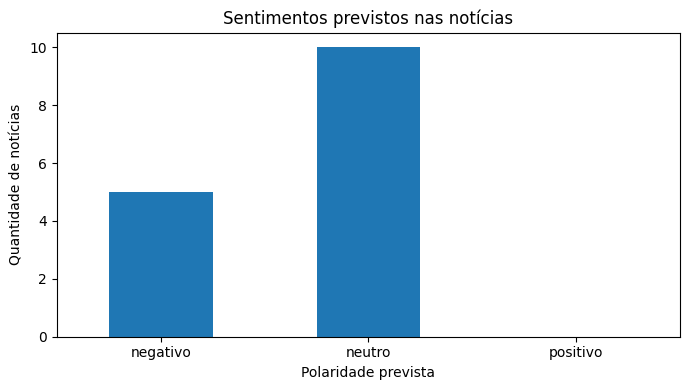

In [11]:
if sentimentos_df.empty:
    print('Sem resultados de sentimento.')
else:
    distribuicao = sentimentos_df['sentimento'].value_counts().reindex(
        ['negativo', 'neutro', 'positivo'], fill_value=0)
    display(distribuicao.rename('quantidade').reset_index().rename(columns={'index':'sentimento'}))
    ax = distribuicao.plot(kind='bar', figsize=(7, 4), rot=0, title='Sentimentos previstos nas notícias')
    ax.set_ylabel('Quantidade de notícias')
    ax.set_xlabel('Polaridade prevista')
    plt.tight_layout()
    plt.savefig(SAIDA / 'distribuicao_sentimentos.png', dpi=160, bbox_inches='tight')
    plt.show()


## 2. Reconhecimento de Entidades Nomeadas (NER)

Seguindo a Aula 9, usamos **spaCy** para identificar spans de nomes e seus tipos. Antes de extrair relações, fazemos uma **inspeção de dependências sintáticas (parsing)** de uma frase do corpus — isso ajuda a entender como o sistema localiza sujeito, verbo e objeto.

**Nota:** o modelo `pt_core_news_sm` não tem necessariamente uma categoria separada para jogador ou clube; a classificação depende das etiquetas disponíveis e do contexto. Não trate toda organização reconhecida como clube.

In [12]:
texto_exemplo = amostra.iloc[0]['_texto_unidade3'][:LIMITE_CARACTERES]
doc_exemplo = nlp(texto_exemplo)
sentenca_exemplo = next(iter(doc_exemplo.sents))
parsing_df = pd.DataFrame([
    {'token':t.text, 'lema':t.lemma_, 'classe':t.pos_,
     'dependencia':t.dep_, 'nucleo':t.head.text}
    for t in sentenca_exemplo
])
print('Título:',amostra.iloc[0]['_titulo_unidade3'])
print('Sentença:',sentenca_exemplo.text)
display(parsing_df)
displacy.render(sentenca_exemplo, style='dep', jupyter=True,
                options={'compact':True,'distance':90})

Título: As disputas comerciais e de poder na formação da liga única
Sentença: a liga única de clubes para organizar o campeonato brasileiro já foi ensaiada no brasil diversas vezes.


,token,lema,classe,dependencia,nucleo
0,a,o,DET,det,liga
1,liga,liga,NOUN,nsubj:pass,ensaiada
2,única,único,ADJ,amod,liga
3,de,de,ADP,case,clubes
4,clubes,clube,NOUN,nmod,liga
5,para,para,SCONJ,mark,organizar
6,organizar,organizar,VERB,acl,liga
7,o,o,DET,det,campeonato
8,campeonato,campeonato,NOUN,obj,organizar
9,brasileiro,brasileiro,ADJ,amod,campeonato


### 2.1. Identificação de entidades nas notícias

O modelo português `pt_core_news_sm` tem taxonomia própria. Verificamos seus rótulos em tempo de execução; não presumimos que ele sempre separe **jogador, clube, campeonato ou estádio**. Também conservamos URL e frase de origem para conferência.

In [13]:
print('Categorias suportadas pelo modelo:', nlp.get_pipe('ner').labels)
linhas_ner=[]
processados=[]
for ix, doc in enumerate(nlp.pipe(amostra['_texto_unidade3'].str.slice(0,LIMITE_CARACTERES).tolist(), batch_size=8)):
    linha=amostra.iloc[ix]
    processados.append((ix,doc))
    for entidade in doc.ents:
        linhas_ner.append({
            'id_amostra':ix,'titulo':linha['_titulo_unidade3'],
            'url':linha['_url_unidade3'],
            'entidade':entidade.text,'categoria':entidade.label_,
            'inicio':entidade.start_char,'fim':entidade.end_char,
            'sentenca_origem':entidade.sent.text.strip(),
            'correta_manual':''
        })
ner_df=pd.DataFrame(linhas_ner,columns=['id_amostra','titulo','url','entidade',
                                       'categoria','inicio','fim','sentenca_origem','correta_manual'])
ner_df.to_csv(SAIDA/'entidades_ner_revisao_manual.csv',index=False)
print('Entidades reconhecidas:',len(ner_df))
display(ner_df.head(25))

Categorias suportadas pelo modelo: ('LOC', 'MISC', 'ORG', 'PER')
Entidades reconhecidas: 505


,id_amostra,titulo,url,entidade,categoria,inicio,fim,sentenca_origem,correta_manual
0,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,campeonato brasileiro,MISC,40,61,a liga única de clubes para organizar o campeo...,
1,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,brasil,LOC,81,87,a liga única de clubes para organizar o campeo...,
2,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,forte união,LOC,271,282,"há alguns anos, mais uma tentativa foi frustra...",
3,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,cbf,ORG,917,920,e também uma disputa interna de poder e influê...,
4,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,imbróglio,PER,1124,1133,conversou nas últimas semanas com pessoas liga...,
5,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,rede globo,ORG,1337,1347,"guerra de emissoras a cazé tv, controlada pela...",
6,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,copa do mundo,MISC,1383,1396,"guerra de emissoras a cazé tv, controlada pela...",
7,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,copa do brasil,MISC,1596,1610,"na guerra comercial, a cazé tv acabou fora da ...",
8,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,cbf,ORG,1629,1632,gente de peso na cbf explicou que não houve um...,
9,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,ffu,ORG,1814,1817,gente de peso na cbf explicou que não houve um...,


In [14]:
if not ner_df.empty:
    frequencia = (ner_df.groupby(['entidade','categoria']).size()
                  .sort_values(ascending=False).head(15))
    display(frequencia.rename('frequencia').reset_index())
    print('Distribuição das categorias:')
    display(ner_df['categoria'].value_counts().rename_axis('categoria').reset_index(name='quantidade'))
else:
    print('Nenhuma entidade detectada nesta amostra. Examine os textos e o modelo.')
displacy.render(doc_exemplo, style='ent', jupyter=True)

,entidade,categoria,frequencia
0,fluminense,ORG,20
1,são paulo,ORG,20
2,flamengo,ORG,17
3,santos,ORG,14
4,libertadores,MISC,13
5,palmeiras,ORG,12
6,vasco,ORG,10
7,corinthians,ORG,9
8,copa sul-americana,MISC,8
9,brasileirão,MISC,8


Distribuição das categorias:


,categoria,quantidade
0,PER,187
1,ORG,161
2,LOC,93
3,MISC,64


In [15]:
# Exemplo visual: entidades reconhecidas na primeira notícia da amostra
if processados:
    indice_exemplo, doc_ner_exemplo = processados[0]
    print('Título:', amostra.iloc[indice_exemplo]['_titulo_unidade3'])
    displacy.render(doc_ner_exemplo[:min(120, len(doc_ner_exemplo))], style='ent', jupyter=True)


Título: As disputas comerciais e de poder na formação da liga única


## 3. Extração de relações

Reaproveitamos o **parsing de dependências** e os **spans do NER**, tal como na Aula 9:

- Para cada verbo, buscamos um sujeito (`nsubj` / `nsubj:pass`) e objeto ou complemento (`obj`, `iobj`, `obl`).
- A relação recebe o **lema do verbo** (`contratou → contratar`). Se houver complemento oblíquo, tentamos incluir a preposição (`atuar_em`).
- Preferimos o nome da entidade detectada pelo NER quando o núcleo sintático está dentro dela.

A saída contém **relações candidatas**, que podem estar erradas; frases na voz passiva, coordenações, pronomes e dependências mal reconhecidas dificultam a extração.

In [16]:
PREPOSICOES = {
    'no':'em','na':'em','nos':'em','nas':'em',
    'do':'de','da':'de','dos':'de','das':'de',
    'ao':'a','aos':'a','à':'a','às':'a',
    'pelo':'por','pela':'por','pelos':'por','pelas':'por'
}


def argumento(token, doc):
    entidade = next((e for e in doc.ents if e.start <= token.i < e.end), None)
    if entidade is not None:
        return entidade.text, entidade.label_
    arvore = sorted((t for t in token.subtree if not t.is_punct), key=lambda t: t.i)
    while arvore and (arvore[0].dep_ in {'det','case'} or arvore[0].pos_ in {'ADP','DET'}):
        arvore.pop(0)
    texto = ' '.join(t.text for t in arvore).strip()
    return texto[:160], ''


def extrair_relacoes_doc(doc, noticia_id, titulo='', url=''):
    linhas = []
    for sent in doc.sents:
        for verbo in sent:
            if verbo.pos_ != 'VERB':
                continue
            sujeitos = [t for t in verbo.children if t.dep_ in {'nsubj','nsubj:pass'}]
            complementos = [t for t in verbo.children if t.dep_ in {'obj','iobj','obl'}]
            for sujeito in sujeitos:
                nome_sujeito, cat_sujeito = argumento(sujeito, doc)
                for comp in complementos:
                    nome_objeto, cat_objeto = argumento(comp, doc)
                    if not nome_sujeito or not nome_objeto:
                        continue
                    prep = next((t for t in comp.children if t.dep_ == 'case'), None)
                    rel = verbo.lemma_.lower() or verbo.text.lower()
                    if comp.dep_ == 'obl' and prep is not None:
                        rel += '_' + PREPOSICOES.get(prep.text.lower(), prep.lemma_.lower())
                    linhas.append({
                        'id_amostra':noticia_id, 'titulo':titulo,'url':url,
                        'sujeito':nome_sujeito, 'categoria_sujeito':cat_sujeito,
                        'relacao':rel,'objeto':nome_objeto,'categoria_objeto':cat_objeto,
                        'sentenca_origem':sent.text.strip(),
                        'possui_ner':bool(cat_sujeito or cat_objeto),
                        'correta_manual':''
                    })
    return linhas

linhas_rel=[]
for ix, doc in processados:
    linha=amostra.iloc[ix]
    linhas_rel.extend(extrair_relacoes_doc(doc,ix,linha['_titulo_unidade3'],linha['_url_unidade3']))
colunas=['id_amostra','titulo','url','sujeito','categoria_sujeito','relacao',
         'objeto','categoria_objeto','sentenca_origem','possui_ner','correta_manual']
relacoes_df=pd.DataFrame(linhas_rel,columns=colunas)
relacoes_df.to_csv(SAIDA/'relacoes_revisao_manual.csv',index=False)
print('Triplas candidatas:',len(relacoes_df))
display(relacoes_df.head(30))

Triplas candidatas: 607


,id_amostra,titulo,url,sujeito,categoria_sujeito,relacao,objeto,categoria_objeto,sentenca_origem,possui_ner,correta_manual
0,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,liga única de clubes para organizar o campeona...,,ensaiar_em,brasil,LOC,a liga única de clubes para organizar o campeo...,True,
1,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,liga única de clubes para organizar o campeona...,,ensaiar,vezes,,a liga única de clubes para organizar o campeo...,False,
2,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,interesses individuais,,rachar,desejo coletivo,,interesses individuais sempre racharam o desej...,False,
3,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,que,,trazer,novas disputas para a mesa,,"e, agora, a cbf tenta reunir as equipes em uma...",False,
4,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,que,,sofrer,ataques nos bastidores,,"o grande entrave, no momento, é o controle dos...",False,
5,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,que,,fazer,parte da ffu,,"guerra de emissoras a cazé tv, controlada pela...",False,
6,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,que,,incomodar,vez é a responsável por negociar os direitos d...,,"guerra de emissoras a cazé tv, controlada pela...",False,
7,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,que,,incomodar,rede globo,ORG,"guerra de emissoras a cazé tv, controlada pela...",True,
8,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,questão,,contribuir,demissões,,a ponto de a questão contribuir para demissões...,False,
9,0,As disputas comerciais e de poder na formação ...,https://www.lance.com.br/futebol-nacional/bast...,questão,,contribuir_em,alta cúpula executiva da emissora de maior alc...,,a ponto de a questão contribuir para demissões...,False,


### 3.1. Avaliação manual de NER e relações

Edite os CSVs gerados e marque **1** (correto) ou **0** (incorreto) nas colunas `correta_manual`. Erros devem ser descritos no relatório: por exemplo, entidade ausente, nome incompleto, confusão entre clube e local, objeto errado ou relação sem contexto. Sem anotação humana, **não informe precisão**.

In [17]:
print('Arquivos para revisão:')
print(SAIDA/'entidades_ner_revisao_manual.csv')
print(SAIDA/'relacoes_revisao_manual.csv')
print('Exemplo de tripla candidata e sentença de origem:')
if relacoes_df.empty:
    print('Nenhuma relação coberta pelas regras nesta amostra.')
else:
    display(relacoes_df[['sujeito','relacao','objeto','sentenca_origem']].head(10))

Arquivos para revisão:
resultados/entidades_ner_revisao_manual.csv
resultados/relacoes_revisao_manual.csv
Exemplo de tripla candidata e sentença de origem:


,sujeito,relacao,objeto,sentenca_origem
0,liga única de clubes para organizar o campeona...,ensaiar_em,brasil,a liga única de clubes para organizar o campeo...
1,liga única de clubes para organizar o campeona...,ensaiar,vezes,a liga única de clubes para organizar o campeo...
2,interesses individuais,rachar,desejo coletivo,interesses individuais sempre racharam o desej...
3,que,trazer,novas disputas para a mesa,"e, agora, a cbf tenta reunir as equipes em uma..."
4,que,sofrer,ataques nos bastidores,"o grande entrave, no momento, é o controle dos..."
5,que,fazer,parte da ffu,"guerra de emissoras a cazé tv, controlada pela..."
6,que,incomodar,vez é a responsável por negociar os direitos d...,"guerra de emissoras a cazé tv, controlada pela..."
7,que,incomodar,rede globo,"guerra de emissoras a cazé tv, controlada pela..."
8,questão,contribuir,demissões,a ponto de a questão contribuir para demissões...
9,questão,contribuir_em,alta cúpula executiva da emissora de maior alc...,a ponto de a questão contribuir para demissões...


### 3.2. Grafo dirigido de entidades e relações

Para legibilidade, incluímos no máximo 20 triplas que tenham ao menos uma entidade identificada pelo modelo. O grafo mostra **o que as regras extraíram**, não conhecimento verificado; cada nó mantém o nome textual, sem resolução de apelidos (ex.: `Timão` e `Corinthians`).

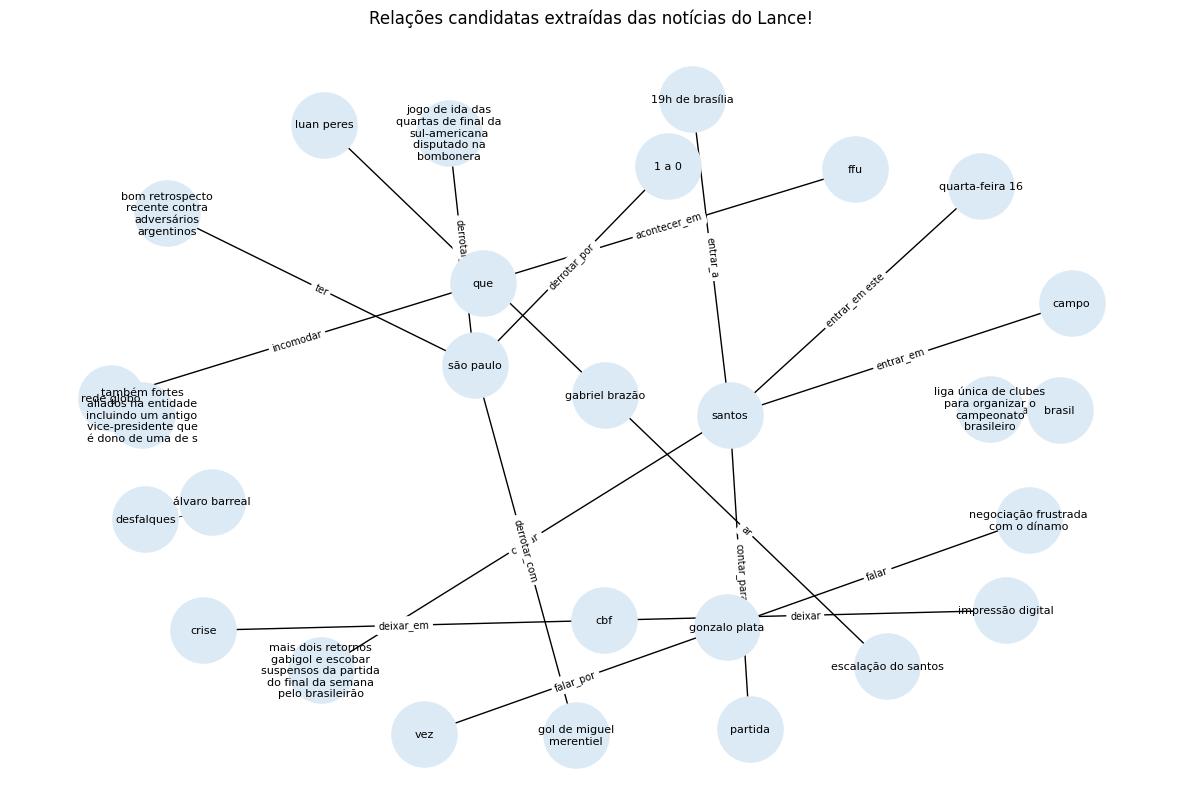

Nós: 28 | Arestas: 20


In [18]:
triplas_grafo = (relacoes_df[relacoes_df['possui_ner']]
                .drop_duplicates(['sujeito','relacao','objeto']).head(20))
G = nx.DiGraph()
for linha in triplas_grafo.itertuples(index=False):
    if G.has_edge(linha.sujeito, linha.objeto):
        G[linha.sujeito][linha.objeto]['relacoes'].add(linha.relacao)
    else:
        G.add_edge(linha.sujeito, linha.objeto, relacoes={linha.relacao})
if G.number_of_edges() == 0:
    print('Nenhuma relação associada a NER para construir grafo.')
else:
    fig, ax=plt.subplots(figsize=(15,10))
    pos=nx.spring_layout(G, seed=SEMENTE)
    nx.draw_networkx_nodes(G,pos,node_color='#dceaf5',node_size=2200,ax=ax)
    rotulos={n:textwrap.fill(str(n),20) for n in G.nodes()}
    nx.draw_networkx_labels(G,pos,labels=rotulos,font_size=8,ax=ax)
    nx.draw_networkx_edges(G,pos,arrows=True,arrowsize=17,ax=ax)
    edge_labels={(u,v):textwrap.fill(', '.join(sorted(d['relacoes'])),18)
                 for u,v,d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G,pos,edge_labels=edge_labels,font_size=7,ax=ax)
    ax.axis('off')
    ax.set_title('Relações candidatas extraídas das notícias do Lance!')
    plt.savefig(SAIDA/'grafo_relacoes_lance.png',dpi=170,bbox_inches='tight')
    plt.show()
    print('Nós:',G.number_of_nodes(),'| Arestas:',G.number_of_edges())

## 4. Resumo e interpretação para a entrega de hoje

Use as tabelas e imagens salvas em `resultados/` para explicar:

1. **Sentimentos:** quantas notícias foram avaliadas, distribuição dos rótulos e ao menos um exemplo discutido criticamente.
2. **NER:** quantas entidades foram reconhecidas, quais categorias apareceram e exemplos de acertos/erros.
3. **Relações:** quantas triplas candidatas foram extraídas, exemplos relevantes, erros e o grafo.

**Atenção:** *sem revisão humana, não declare acurácia/precisão*. Evite afirmar que notícias, sentimentos e relações gerados automaticamente são necessariamente verdadeiros.

O PDF do Trabalho da Unidade 3 permite amostras menores **desde que explicitadas** e exige mencionar ferramentas de IA utilizadas, incluindo fornecedor, modelo e prompts. Neste notebook, cite também o modelo de sentimento e o spaCy usados no experimento.

In [19]:
resumo = {
    'base': str(caminho_base),
    'noticias_disponiveis': len(base),
    'amostra_ner_relacoes': len(amostra),
    'amostra_sentimentos': len(sentimentos_df),
    'limite_caracteres_ner_relacoes': LIMITE_CARACTERES,
    'limite_tokens_sentimentos': MAX_TOKENS_SENTIMENTOS,
    'modelo_sentimentos': MODELO_SENTIMENTOS,
    'modelo_ner_relacoes': 'spacy/pt_core_news_sm',
    'entidades_reconhecidas': len(ner_df),
    'triplas_candidatas': len(relacoes_df),
    'distribuicao_sentimentos': sentimentos_df['sentimento'].value_counts().to_dict(),
}
with (SAIDA / 'resumo_experimentos.json').open('w', encoding='utf-8') as arquivo:
    json.dump(resumo, arquivo, ensure_ascii=False, indent=2)
print(json.dumps(resumo, ensure_ascii=False, indent=2))
print()
print('Arquivos produzidos em:', SAIDA.resolve())
print('- sentimentos_lance.csv / distribuicao_sentimentos.png')
print('- entidades_ner_revisao_manual.csv / relacoes_revisao_manual.csv')
print('- grafo_relacoes_lance.png (se houver relações para desenhar)')
print('- resumo_experimentos.json')


{
  "base": "/content/noticias_lance_processadas.csv",
  "noticias_disponiveis": 500,
  "amostra_ner_relacoes": 25,
  "amostra_sentimentos": 15,
  "limite_caracteres_ner_relacoes": 2500,
  "limite_tokens_sentimentos": 256,
  "modelo_sentimentos": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
  "modelo_ner_relacoes": "spacy/pt_core_news_sm",
  "entidades_reconhecidas": 505,
  "triplas_candidatas": 607,
  "distribuicao_sentimentos": {
    "neutro": 10,
    "negativo": 5
  }
}

Arquivos produzidos em: /content/resultados
- sentimentos_lance.csv / distribuicao_sentimentos.png
- entidades_ner_revisao_manual.csv / relacoes_revisao_manual.csv
- grafo_relacoes_lance.png (se houver relações para desenhar)
- resumo_experimentos.json
